In [311]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [312]:
df=pd.read_csv("/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv")

In [313]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [314]:
df.dropna(inplace=True)

df.isna().sum()
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [315]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   ocean_proximity     20433 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


In [316]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000
mean,-119.570689,35.633221,28.633094,2636.504233,537.870553,1424.946949,499.433465,3.871162,206864.413155
std,2.003578,2.136348,12.591805,2185.269567,421.385070,1133.208490,382.299226,1.899291,115435.667099
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1450.000000,296.000000,787.000000,280.000000,2.563700,119500.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.536500,179700.000000
75%,-118.010000,37.720000,37.000000,3143.000000,647.000000,1722.000000,604.000000,4.744000,264700.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [317]:
from sklearn.model_selection import train_test_split
df1=df.drop("median_house_value",axis=1)
y=df["median_house_value"]
X_train, X_test, y_train, y_test= train_test_split(df1,y,test_size=0.2)

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

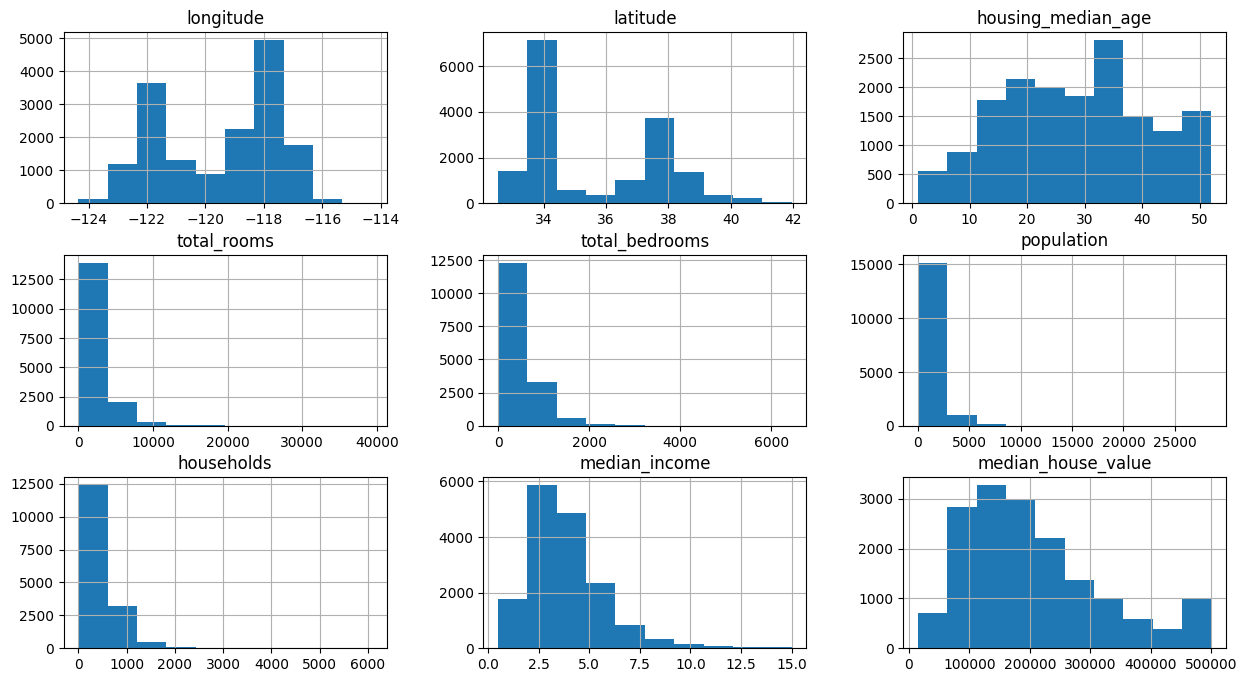

In [318]:
Train_data= X_train.join(y_train)
Train_data.hist(figsize=(15,8))

In [319]:
def corr_mat(x):
    numeric_df=x.select_dtypes(include=[np.number])
    mat_corr=numeric_df.corr()
    sns.heatmap(mat_corr,annot=True,fmt=".2f",cmap="coolwarm")
    plt.title("Correlation Matrix")
    plt.figure(figsize=(20,13))
    plt.show()

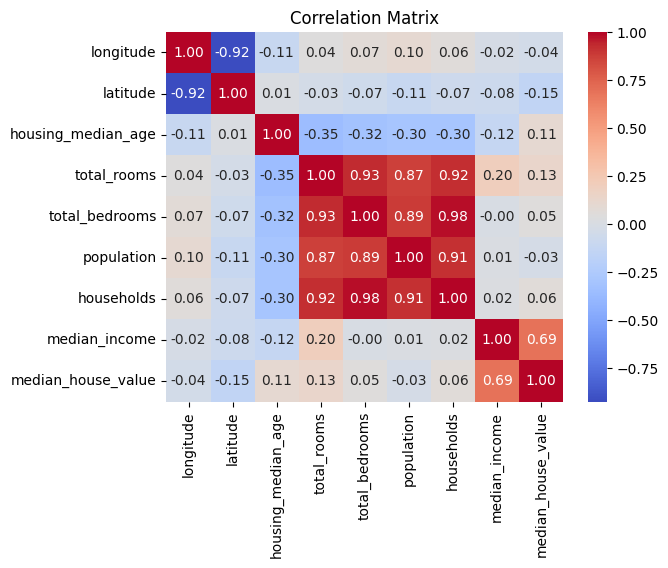

<Figure size 2000x1300 with 0 Axes>

In [320]:
corr_mat(Train_data)


array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

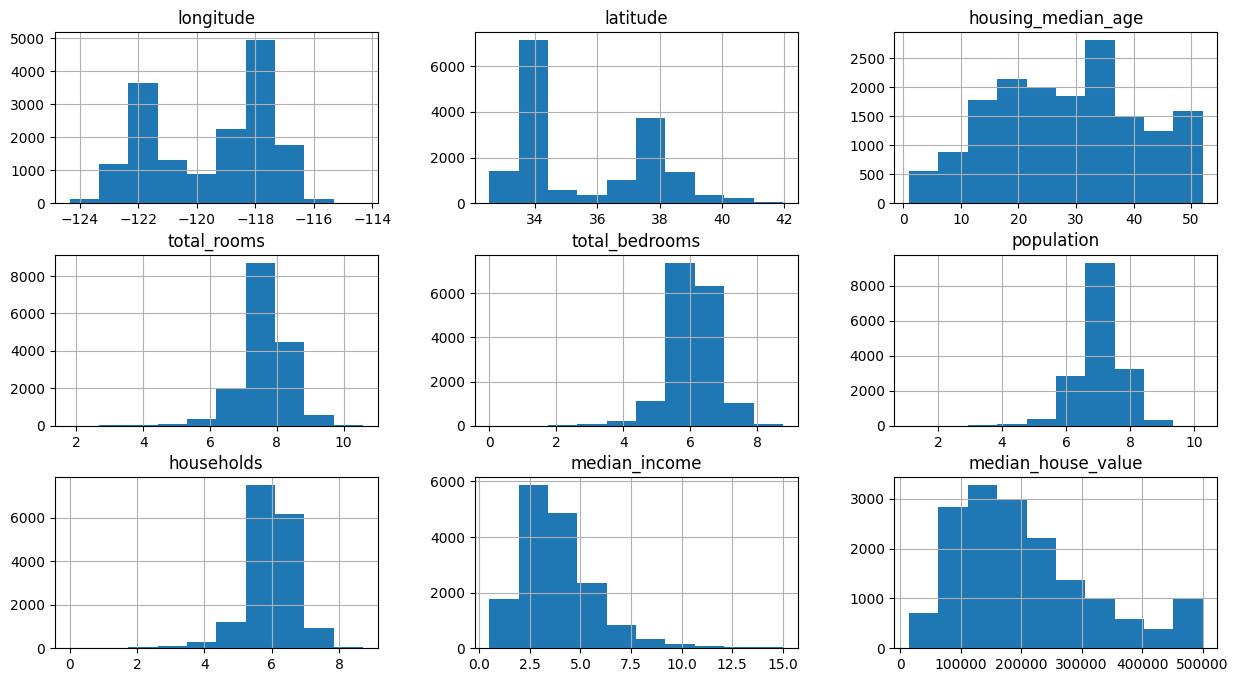

In [321]:
for i in ['households','total_rooms','total_bedrooms', 'population']:
    Train_data[i]=np.log(Train_data[i])
Train_data.hist(figsize=(15,8))



In [322]:
Train_data["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     7183
INLAND        5229
NEAR OCEAN    2112
NEAR BAY      1819
ISLAND           3
Name: count, dtype: int64

In [323]:
pd1=pd.get_dummies(Train_data.ocean_proximity,dtype=int)
Train_data=Train_data.join(pd1).drop(['ocean_proximity'],axis=1)
Train_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
11498,-118.04,33.72,14.0,8.410498,6.954639,7.706163,6.870053,4.7821,169400.0,1,0,0,0,0
19936,-119.33,36.30,12.0,7.683404,5.863631,6.920672,5.869297,4.9464,115600.0,0,1,0,0,0
10569,-117.69,33.66,5.0,8.353733,6.535241,7.566828,6.582025,6.9501,225700.0,1,0,0,0,0
19690,-121.63,39.12,34.0,7.596392,5.852202,6.689599,5.840642,3.4492,98800.0,0,1,0,0,0
7464,-118.19,33.93,42.0,7.511525,5.968708,7.386471,5.932245,3.1912,146400.0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12843,-121.37,38.69,29.0,7.651120,5.940171,7.024649,5.958425,3.0833,87000.0,0,1,0,0,0
13054,-121.27,38.62,13.0,7.749753,6.289716,6.971669,6.208590,2.7652,95600.0,0,1,0,0,0
18921,-122.18,38.07,10.0,8.512382,6.744059,7.644441,6.688355,5.3288,201800.0,0,0,0,1,0
20128,-118.93,34.36,33.0,7.481556,5.733341,6.976348,5.690359,4.6607,187900.0,1,0,0,0,0


In [324]:
Train_data.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
<1H OCEAN               int64
INLAND                  int64
ISLAND                  int64
NEAR BAY                int64
NEAR OCEAN              int64
dtype: object

In [325]:
def corr_mat1(x):
    numeric_df=x.select_dtypes(include=[np.number,bool])
    mat_corr=numeric_df.corr()
    sns.heatmap(mat_corr,annot=True,fmt=".2f",cmap="coolwarm")
    plt.title("Correlation Matrix")
    plt.figure(figsize=(15,8))
    plt.show()
    

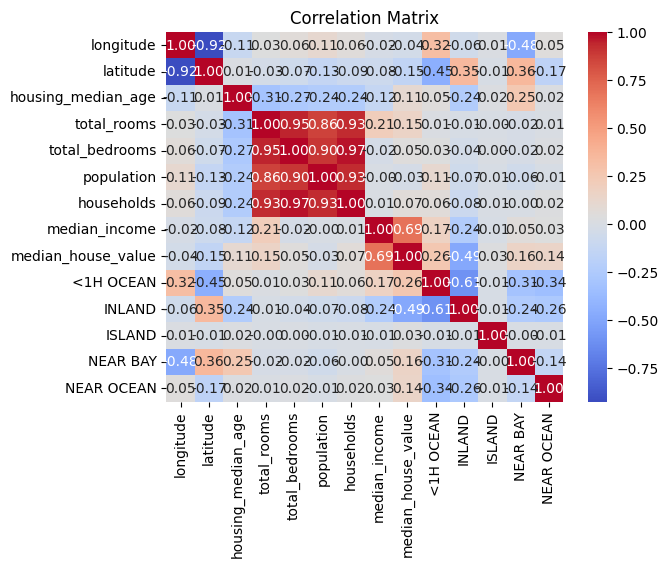

<Figure size 1500x800 with 0 Axes>

In [326]:
corr_mat1(Train_data)

In [327]:
#from sklearn.linear_model import LinearRegression
x_train,Y_train=Train_data.drop(["median_house_value"], axis=1),Train_data["median_house_value"]
#reg=LinearRegression()
#reg.fit(x_train,Y_train)


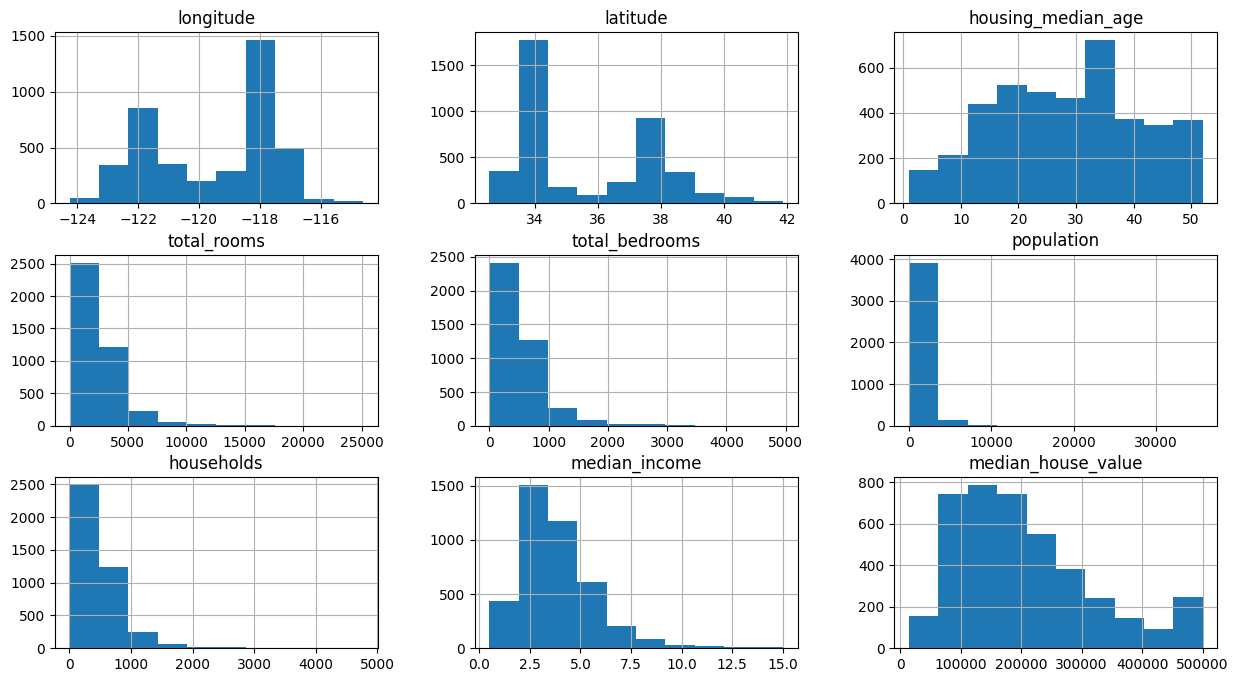

In [328]:
Test_data= X_test.join(y_test)
Test_data.hist(figsize=(15,8))
for i in ['households','total_rooms','total_bedrooms', 'population']:
    Test_data[i]=np.log(Test_data[i])
pd2=pd.get_dummies(Test_data.ocean_proximity,dtype=int)
Test_data=Test_data.join(pd2).drop(['ocean_proximity'],axis=1)

In [329]:
#from sklearn.linear_model import LinearRegression
x_test,Y_test=Test_data.drop(["median_house_value"], axis=1),Test_data["median_house_value"]
#reg=LinearRegression()
#reg.fit(x_test,Y_test)

In [330]:
#reg.score(x_test,Y_test)

In [331]:
from sklearn.ensemble import RandomForestRegressor
forest=RandomForestRegressor()
forest.fit(x_train,Y_train)

RandomForestRegressor()

In [332]:
reg.score(x_test,Y_test)

0.6526985691906484

In [333]:
x_test

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
13435,-117.44,34.10,43.0,7.386471,5.991465,6.830874,5.855072,2.0750,0,1,0,0,0
5593,-118.25,33.80,36.0,7.436617,5.976351,7.149917,5.981414,3.3500,1,0,0,0,0
15482,-117.14,33.15,16.0,7.029088,5.288267,6.630683,5.181784,5.0346,1,0,0,0,0
15071,-116.98,32.79,32.0,8.231110,6.495266,7.384610,6.393591,3.8667,1,0,0,0,0
9078,-118.14,34.69,48.0,7.229114,5.789960,6.545350,5.717028,2.1167,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
19138,-122.69,38.32,16.0,8.227108,6.548219,7.569412,6.489205,4.6324,1,0,0,0,0
4423,-118.25,34.07,43.0,6.638568,5.774552,7.150701,5.723585,2.0000,1,0,0,0,0
6536,-118.06,34.04,28.0,7.323831,5.894403,6.918695,5.840642,2.6288,1,0,0,0,0
15023,-117.01,32.76,22.0,8.195885,6.714171,7.495542,6.645091,2.8594,1,0,0,0,0
